### EXPLAINING THE LAYERS IN A CNN


In [33]:
import tensorflow as tf

# The convilusional layer is responsible for extraxting features from a image.. 
# it extracts unique features from the photo. What seperates a photo from another something something 

# Then we have many filters that come in 16, 32, 64,128 that try to extract features from the image that uniquly identifies the image 

model = tf.keras.Sequential ([
# 32 is batch size,represents each of the images
# The batch size is like the images that come in and acts like a rate limiter
    tf.keras.Input(shape=(224, 224, 3)),  # each image is 224 x 224 with 3 colour channels (the 32 is the batch size, set when training)
# 32 filters size of the filter is (3,3)
# scanss through the image and identifies uniques features
# (222 x 222 x 32)
# this layer reduces the dimention of the features being generated before the final part 
# Flatten scans through the images and generates the image but with less dimentions 
    tf.keras.layers.Conv2D(32, (3,3), activation = "relu"),
# reduce the spacial size of the image (111 x 111 x 32), we would see more prominant features but isnt the goal as it still isnt unique enough
    tf.keras.layers.MaxPooling2D(), 


# at this layer the number of filters increase, and remove what is not necessary in the images 
# (109 x 109 x 64)
    tf.keras.layers.Conv2D(64, (3,3), activation = "relu"),
    tf.keras.layers.MaxPooling2D(), #(54 x 54 x 64)
# by the time the images is here its dimentions are reduced even further 
# (34 x 34 x 128)
    tf.keras.layers.Conv2D(128, (3,3), activation = "relu"),
    tf.keras.layers.MaxPooling2D(), #(25 x 25 x 128) we have extracted the features from the images and we can now pass it to the network but we need to convert it to a vector so it can understand the images 

    tf.keras.layers.Flatten(), # this happens here by multiplying the dimentions (32,67 897), basically generates a vector for ther 32 images in the batch

# this is the deep learning network 
# we retain the number of filters of 128 
# this wants to reduce the image as much as possible, to tell us if it is a dog or a cat 
# 
    tf.keras.layers.Dense(128, activation = "relu"), # (32, 128) from here it can then decide if it is a dog or a cat
# we use 1 here because it is a dog or cat (binary classification), this will return a probability and we can use this to classify it
    tf.keras.layers.Dense(1, activation = "sigmoid"), # we 
# in the case of a multiclassification problem it woul look like this:
# when we deal with multiclass we cant really use sigmoid but we can use softmax 
    tf.keras.layers.Dense(5, activation = "softmax"),

]) 

SyntaxError: invalid syntax. Maybe you meant '==' or ':=' instead of '='? (3643767188.py, line 9)

In [3]:
import os 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#CNN LAYER
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, AveragePooling2D, Flatten, Dense, Dropout
)
# Data Augmentation 
from tensorflow.keras.layers import(
    RandomFlip, RandomRotation, RandomZoom, RandomContrast, RandomTranslation
)


In [6]:
# check for corrupt images, file size, 2 folders for cats and dogs but for EDA we need to check the classes that are here 
# check avaliable classes 
base_dir = "PetImages"
for class_name in os.listdir(base_dir):
    class_path = os.path.join(base_dir,class_name)

    if os.path.isdir(class_path):
        print(f"\n{class_name}")
        print("Number of files: ", len(os.listdir(class_path)))



Cat
Number of files:  12499

Dog
Number of files:  12499


In [8]:
# count the number of images 

class_counts = {}
for class_name in os.listdir(base_dir):
    class_path = os.path.join(base_dir,class_name)


    if os.path.isdir(class_path):
        class_counts[class_name] = len(os.listdir(class_path))


print(class_counts)

{'Cat': 12499, 'Dog': 12499}


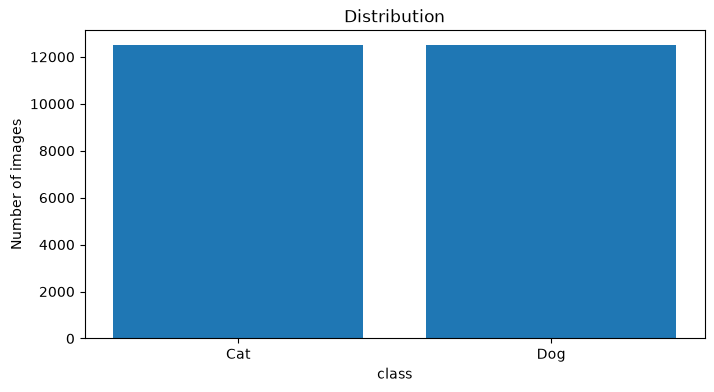

In [10]:
#visualise the classes 

plt.figure(figsize=(8,4))
plt.bar(class_counts.keys(), class_counts.values())
plt.xlabel("class")
plt.ylabel("Number of images")
plt.title("Distribution")
plt.show()

In [11]:
#So classes are balanced 

In [13]:
#So the next thing to do is to check for corrupt images using a pilow function to check if it is corrupt and to check the file extentions 
# check for corrupt images and wrong file extentions 

from PIL import Image




In [17]:
# This is where you can delete or remove a file if it doesnt match the file extentions and if it is corrupt
valid_extensions = (".jpg",".jpeg",".png",".bmp",".gif")
corrupted_images = []
invalid_files = []

for class_name in os.listdir(base_dir):
    class_path = os.path.join(base_dir,class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):
        file_path = os.path.join(class_path, filename)
#look at invalid file path extentions 
        if not filename.lower().endswith(valid_extensions):
            invlaid_files.append(file_path)
            continue
        try:
            with Image.open(file_path) as img:
                #checks if the image is corrupt or not
                img.verify()
        except Exception:
            corrupted_images.append(file_path)

print("Corru[t images: ", len(corrupted_images))
print("Invalid Files: ", len(invalid_files))

Corru[t images:  0
Invalid Files:  0


In [21]:
# Remove a corrupt file if they do exist 
for image_path in invalid_files:
    if os.path.exists(image_path):
        os.remove(image_path)
print("Invalid files removed")

Invalid files removed


In [20]:

# for corru[ted images 
for image_path in corrupted_images:
    if os.path.exists(image_path):
        os.remove(image_path)
print("Corrupted images removed")

Corrupted images removed


In [24]:
# check the dimentions of the images because we are going to resize them and we are going to make them all of them the same size 
# we can part the image to keep the resolution of the image or we can crop the images to make them the same size but we could loose part of the images 
image_dimension = []

for class_name in os.listdir(base_dir):
    class_path = os.path.join(base_dir,class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):
        file_path = os.path.join(class_path, filename)
# open the file and check the size of the file append to the array 
        try:
            with Image.open(file_path) as img:
                width, height = img.size

                image_dimension.append({
                    "class": class_name,
                    "width": width,
                    "height": height
                })
        except Exception:
            pass

    

/opt/anaconda3/envs/tf-metal/lib/python3.11/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


In [25]:
# convert to df
dim_df = pd.DataFrame(image_dimension)
dim_df.head()

,class,width,height
0,Cat,365,500
1,Cat,500,375
2,Cat,320,240
3,Cat,500,417
4,Cat,500,375


In [26]:
dim_df.describe()

,width,height
count,24998.000000,24998.000000
mean,404.447196,360.989239
std,108.999959,97.005417
min,4.000000,4.000000
25%,323.000000,302.000000
50%,448.000000,375.000000
75%,500.000000,421.000000
max,500.000000,500.000000


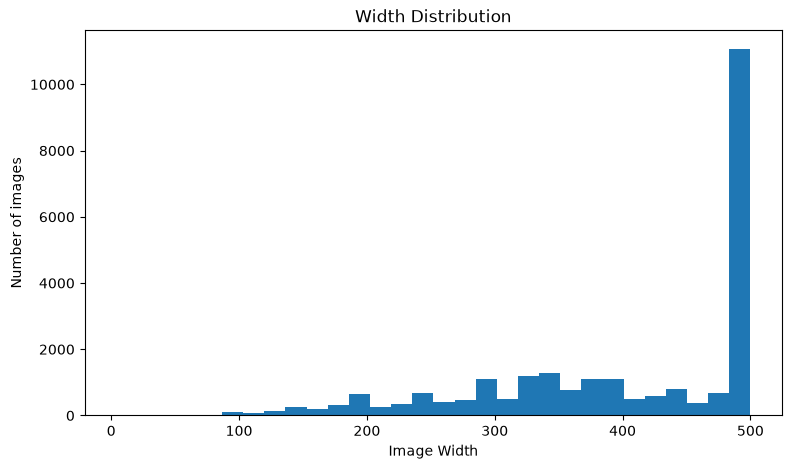

In [27]:
# plot the graphs for the deviations 
plt.figure(figsize=(9,5))
plt.hist(dim_df["width"], bins=30)
plt.xlabel("Image Width")
plt.ylabel("Number of images")
plt.title("Width Distribution")
plt.show()

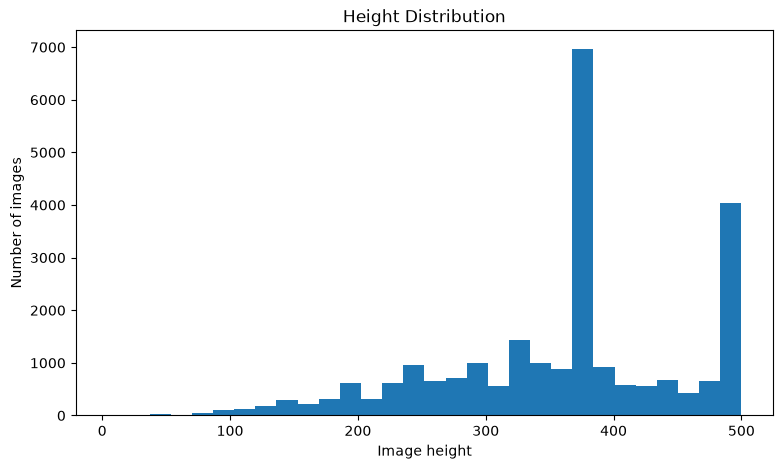

In [29]:
#check hieght 
plt.figure(figsize=(9,5))
plt.hist(dim_df["height"], bins=30)
plt.xlabel("Image height")
plt.ylabel("Number of images")
plt.title("Height Distribution")
plt.show()

In [31]:
# Next we need to get the aspect ratio to see if we have portrait or landscape photos to make sure we dont get distorted images
# this affects the effectiveness of the CNN 
# determines whether we are going to part or crop the images 
